In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Cell 2: Load and inspect the dataset

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "data/data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())


Dataset shape: (1372, 5)

First five rows:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [5]:

# Cell 3: Prepare features, target, and train-test split

# All four features for the final model comparison
X = df[["variance", "skewness", "curtosis", "entropy"]]

# Target labels
y = df["class"]

# Split once so all models use the same training and testing records
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Select two features for 2D decision-boundary plots
X_train_2d = X_train[["variance", "skewness"]]
X_test_2d = X_test[["variance", "skewness"]]

print("Full feature dataset:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTwo-feature dataset:")
print("X_train_2d:", X_train_2d.shape)
print("X_test_2d:", X_test_2d.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Full feature dataset:
X_train: (1097, 4)
X_test: (275, 4)

Two-feature dataset:
X_train_2d: (1097, 2)
X_test_2d: (275, 2)

Training class distribution:
class
0    609
1    488
Name: count, dtype: int64

Testing class distribution:
class
0    153
1    122
Name: count, dtype: int64


In [6]:

# Cell 4: Implement Gini impurity and entropy from scratch

def gini_impurity(y):
    """
    Calculate the Gini impurity of a group of labels.
    Lower Gini means the group is more pure.
    """
    y = np.asarray(y)

    # An empty group has zero impurity
    if len(y) == 0:
        return 0.0

    # Count the samples belonging to each class
    _, counts = np.unique(y, return_counts=True)

    # Convert class counts into proportions
    probabilities = counts / len(y)

    # Gini = 1 - sum of squared class probabilities
    return float(1 - np.sum(probabilities ** 2))


def entropy(y):
    """
    Calculate the entropy of a group of labels.
    Lower entropy means the group is more pure.
    """
    y = np.asarray(y)

    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    # Ignore zero probabilities before calculating logarithms
    probabilities = probabilities[probabilities > 0]

    # Entropy = -sum(p * log2(p))
    return float(-np.sum(probabilities * np.log2(probabilities)))


print("Impurity functions created successfully!")


Impurity functions created successfully!


In [7]:

# Cell 5: Test Gini impurity and entropy

mixed_group = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1])
pure_group = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

print("Mixed group (6 zeros, 4 ones)")
print("Gini:", round(gini_impurity(mixed_group), 4))
print("Entropy:", round(entropy(mixed_group), 4))

print("\nPure group (10 zeros)")
print("Gini:", round(gini_impurity(pure_group), 4))
print("Entropy:", round(entropy(pure_group), 4))


Mixed group (6 zeros, 4 ones)
Gini: 0.48
Entropy: 0.971

Pure group (10 zeros)
Gini: 0.0
Entropy: -0.0


In [8]:

# Cell 6: Find the best feature and threshold from scratch

def calculate_impurity(y, criterion="gini"):
    """Calculate impurity using Gini or entropy."""

    if criterion == "gini":
        return gini_impurity(y)
    elif criterion == "entropy":
        return entropy(y)
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'.")


def find_best_split(X, y, criterion="gini", feature_names=None):
    """
    Find the feature and threshold that give the greatest
    reduction in impurity. Uses NumPy, not a sklearn tree.
    """

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    n_samples, n_features = X.shape

    if n_samples < 2:
        return None

    # Impurity before splitting
    parent_impurity = calculate_impurity(y, criterion)

    best_split = None
    best_gain = 0.0

    # Try every feature
    for feature_idx in range(n_features):

        # Sort distinct values for this feature
        unique_values = np.unique(X[:, feature_idx])

        # A constant feature cannot create a split
        if len(unique_values) < 2:
            continue

        # Thresholds halfway between consecutive values
        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2.0

        # Test every threshold
        for threshold in thresholds:

            left_mask = X[:, feature_idx] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            # Never allow an empty child group
            if len(y_left) == 0 or len(y_right) == 0:
                continue

            # Weighted impurity of the two child groups
            weighted_impurity = (
                len(y_left) / n_samples
                * calculate_impurity(y_left, criterion)
                +
                len(y_right) / n_samples
                * calculate_impurity(y_right, criterion)
            )

            # Reduction in impurity
            gain = parent_impurity - weighted_impurity

            # Keep the best split found so far
            if gain > best_gain + 1e-12:

                if feature_names is not None:
                    feature_name = feature_names[feature_idx]
                else:
                    feature_name = f"feature_{feature_idx}"

                best_gain = gain

                best_split = {
                    "feature_index": feature_idx,
                    "feature_name": feature_name,
                    "threshold": float(threshold),
                    "parent_impurity": float(parent_impurity),
                    "weighted_impurity": float(weighted_impurity),
                    "gain": float(gain)
                }

    # None means no split reduced impurity
    return best_split


print("Best-split function created successfully!")


Best-split function created successfully!


In [9]:

# Cell 7: Test best-split selection on a tiny dataset

X_toy = np.array([
    [1.0],
    [2.0],
    [3.0],
    [4.0],
    [5.0],
    [6.0]
])

y_toy = np.array([0, 0, 0, 1, 1, 1])

toy_split = find_best_split(
    X_toy,
    y_toy,
    criterion="gini",
    feature_names=["example_feature"]
)

print("Best split:", toy_split)


Best split: {'feature_index': 0, 'feature_name': 'example_feature', 'threshold': 3.5, 'parent_impurity': 0.5, 'weighted_impurity': 0.0, 'gain': 0.5}


In [10]:

# Cell 8: Find the first split in the Banknote dataset

feature_names_2d = ["variance", "skewness"]

for criterion in ["gini", "entropy"]:

    result = find_best_split(
        X_train_2d,
        y_train,
        criterion=criterion,
        feature_names=feature_names_2d
    )

    print(f"\nCriterion: {criterion}")

    if result is not None:
        print("Selected feature:", result["feature_name"])
        print("Threshold:", result["threshold"])
        print("Parent impurity:", result["parent_impurity"])
        print("Weighted impurity:", result["weighted_impurity"])
        print("Impurity reduction:", result["gain"])
    else:
        print("No improving split found.")



Criterion: gini
Selected feature: variance
Threshold: 0.7651
Parent impurity: 0.4939168645074119
Weighted impurity: 0.25182235494123956
Impurity reduction: 0.24209450956617234

Criterion: entropy
Selected feature: variance
Threshold: 0.7651
Parent impurity: 0.9912060080005995
Weighted impurity: 0.5884013822087819
Impurity reduction: 0.40280462579181764


In [11]:

# Cell 9: Complete Decision Tree implementation from scratch

class ManualDecisionTree:

    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_gain=1e-12
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("Criterion must be 'gini' or 'entropy'.")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_gain = min_gain

    def fit(self, X, y):
        """Build the tree using the training data."""

        if hasattr(X, "columns"):
            self.feature_names_ = list(X.columns)
        else:
            X = np.asarray(X)
            self.feature_names_ = [
                f"feature_{i}" for i in range(X.shape[1])
            ]

        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2:
            raise ValueError("X must be a 2D feature matrix.")

        if len(X) != len(y) or len(y) == 0:
            raise ValueError("X and y must have matching, nonempty rows.")

        if len(self.feature_names_) != X.shape[1]:
            raise ValueError("Feature names do not match X.")

        self.n_features_in_ = X.shape[1]

        # Start recursive tree building at depth zero
        self.root_ = self._build_tree(X, y, depth=0)

        return self

    def _majority_class(self, y):
        """Return the most frequent label in a group."""

        labels, counts = np.unique(y, return_counts=True)
        return labels[np.argmax(counts)]

    def _make_leaf(self, y):
        """Create a leaf that predicts the majority class."""

        return {
            "type": "leaf",
            "prediction": self._majority_class(y),
            "samples": len(y),
            "impurity": calculate_impurity(y, self.criterion)
        }

    def _build_tree(self, X, y, depth):
        """Recursively build the decision tree."""

        # Stopping condition 1: the group is pure
        if len(np.unique(y)) == 1:
            return self._make_leaf(y)

        # Stopping condition 2: maximum tree depth reached
        if (
            self.max_depth is not None
            and depth >= self.max_depth
        ):
            return self._make_leaf(y)

        # Stopping condition 3: too few samples to split
        if len(y) < self.min_samples_split:
            return self._make_leaf(y)

        # Find the best feature and threshold
        split = find_best_split(
            X,
            y,
            criterion=self.criterion,
            feature_names=self.feature_names_
        )

        # Stopping condition 4: no useful split exists
        if split is None or split["gain"] <= self.min_gain:
            return self._make_leaf(y)

        feature_idx = split["feature_index"]
        threshold = split["threshold"]

        left_mask = X[:, feature_idx] <= threshold
        right_mask = ~left_mask

        # Build left and right subtrees recursively
        left_child = self._build_tree(
            X[left_mask], y[left_mask], depth + 1
        )

        right_child = self._build_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        # Save the decision node
        return {
            "type": "node",
            "feature_index": feature_idx,
            "feature_name": split["feature_name"],
            "threshold": threshold,
            "gain": split["gain"],
            "samples": len(y),
            "impurity": split["parent_impurity"],
            "prediction": self._majority_class(y),
            "left": left_child,
            "right": right_child
        }

    def _predict_one(self, row):
        """Predict the class of one sample."""

        node = self.root_

        while node["type"] == "node":

            feature_idx = node["feature_index"]
            threshold = node["threshold"]

            if row[feature_idx] <= threshold:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):
        """Predict classes for multiple samples."""

        if not hasattr(self, "root_"):
            raise RuntimeError("Fit the tree before predicting.")

        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Unexpected number of input features.")

        return np.asarray([
            self._predict_one(row) for row in X
        ])

    def _depth(self, node):
        """Calculate the depth of the learned tree."""

        if node["type"] == "leaf":
            return 0

        return 1 + max(
            self._depth(node["left"]),
            self._depth(node["right"])
        )

    def get_depth(self):
        return self._depth(self.root_)

    def _count_leaves(self, node):
        if node["type"] == "leaf":
            return 1

        return (
            self._count_leaves(node["left"])
            + self._count_leaves(node["right"])
        )

    def get_n_leaves(self):
        return self._count_leaves(self.root_)

    def _print_rules(self, node, indent=""):
        """Print the rules learned by the manual tree."""

        if node["type"] == "leaf":
            print(
                f"{indent}Predict class {node['prediction']} "
                f"(samples={node['samples']}, "
                f"impurity={node['impurity']:.4f})"
            )
            return

        name = node["feature_name"]
        threshold = node["threshold"]

        print(f"{indent}IF {name} <= {threshold:.4f}:")
        self._print_rules(node["left"], indent + "    ")

        print(f"{indent}ELSE ({name} > {threshold:.4f}):")
        self._print_rules(node["right"], indent + "    ")

    def print_rules(self):
        """Display the full tree as human-readable rules."""

        self._print_rules(self.root_)


print("Manual Decision Tree class created successfully!")


Manual Decision Tree class created successfully!


In [12]:

# Cell 10: Train and evaluate the manual Decision Tree

manual_tree_2d = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

manual_tree_2d.fit(X_train_2d, y_train)

# Predict classes for unseen test samples
manual_predictions_2d = manual_tree_2d.predict(X_test_2d)

# Evaluate predictions
manual_accuracy_2d = accuracy_score(
    y_test, manual_predictions_2d
)

print("Manual Decision Tree — 2 features")
print("---------------------------------")
print("Criterion:", manual_tree_2d.criterion)
print("Maximum depth setting:", manual_tree_2d.max_depth)
print("Learned tree depth:", manual_tree_2d.get_depth())
print("Number of leaves:", manual_tree_2d.get_n_leaves())
print(f"Test accuracy: {manual_accuracy_2d:.4f}")
print(f"Test accuracy (%): {manual_accuracy_2d * 100:.2f}%")


Manual Decision Tree — 2 features
---------------------------------
Criterion: gini
Maximum depth setting: 5
Learned tree depth: 5
Number of leaves: 22
Test accuracy: 0.9309
Test accuracy (%): 93.09%


In [13]:

# Cell 11: Display the learned tree rules

print("LEARNED DECISION TREE RULES")
print("===========================")

manual_tree_2d.print_rules()


LEARNED DECISION TREE RULES
IF variance <= 0.7651:
    IF skewness <= 5.1608:
        IF variance <= 0.3202:
            IF variance <= -0.4586:
                IF skewness <= 0.0548:
                    Predict class 1 (samples=208, impurity=0.0000)
                ELSE (skewness > 0.0548):
                    Predict class 1 (samples=138, impurity=0.1219)
            ELSE (variance > -0.4586):
                IF skewness <= -0.1666:
                    Predict class 1 (samples=27, impurity=0.4664)
                ELSE (skewness > -0.1666):
                    Predict class 1 (samples=40, impurity=0.0488)
        ELSE (variance > 0.3202):
            IF skewness <= 3.2197:
                IF variance <= 0.7406:
                    Predict class 0 (samples=34, impurity=0.4723)
                ELSE (variance > 0.7406):
                    Predict class 1 (samples=5, impurity=0.3200)
            ELSE (skewness > 3.2197):
                Predict class 1 (samples=12, impurity=0.0000)
    E

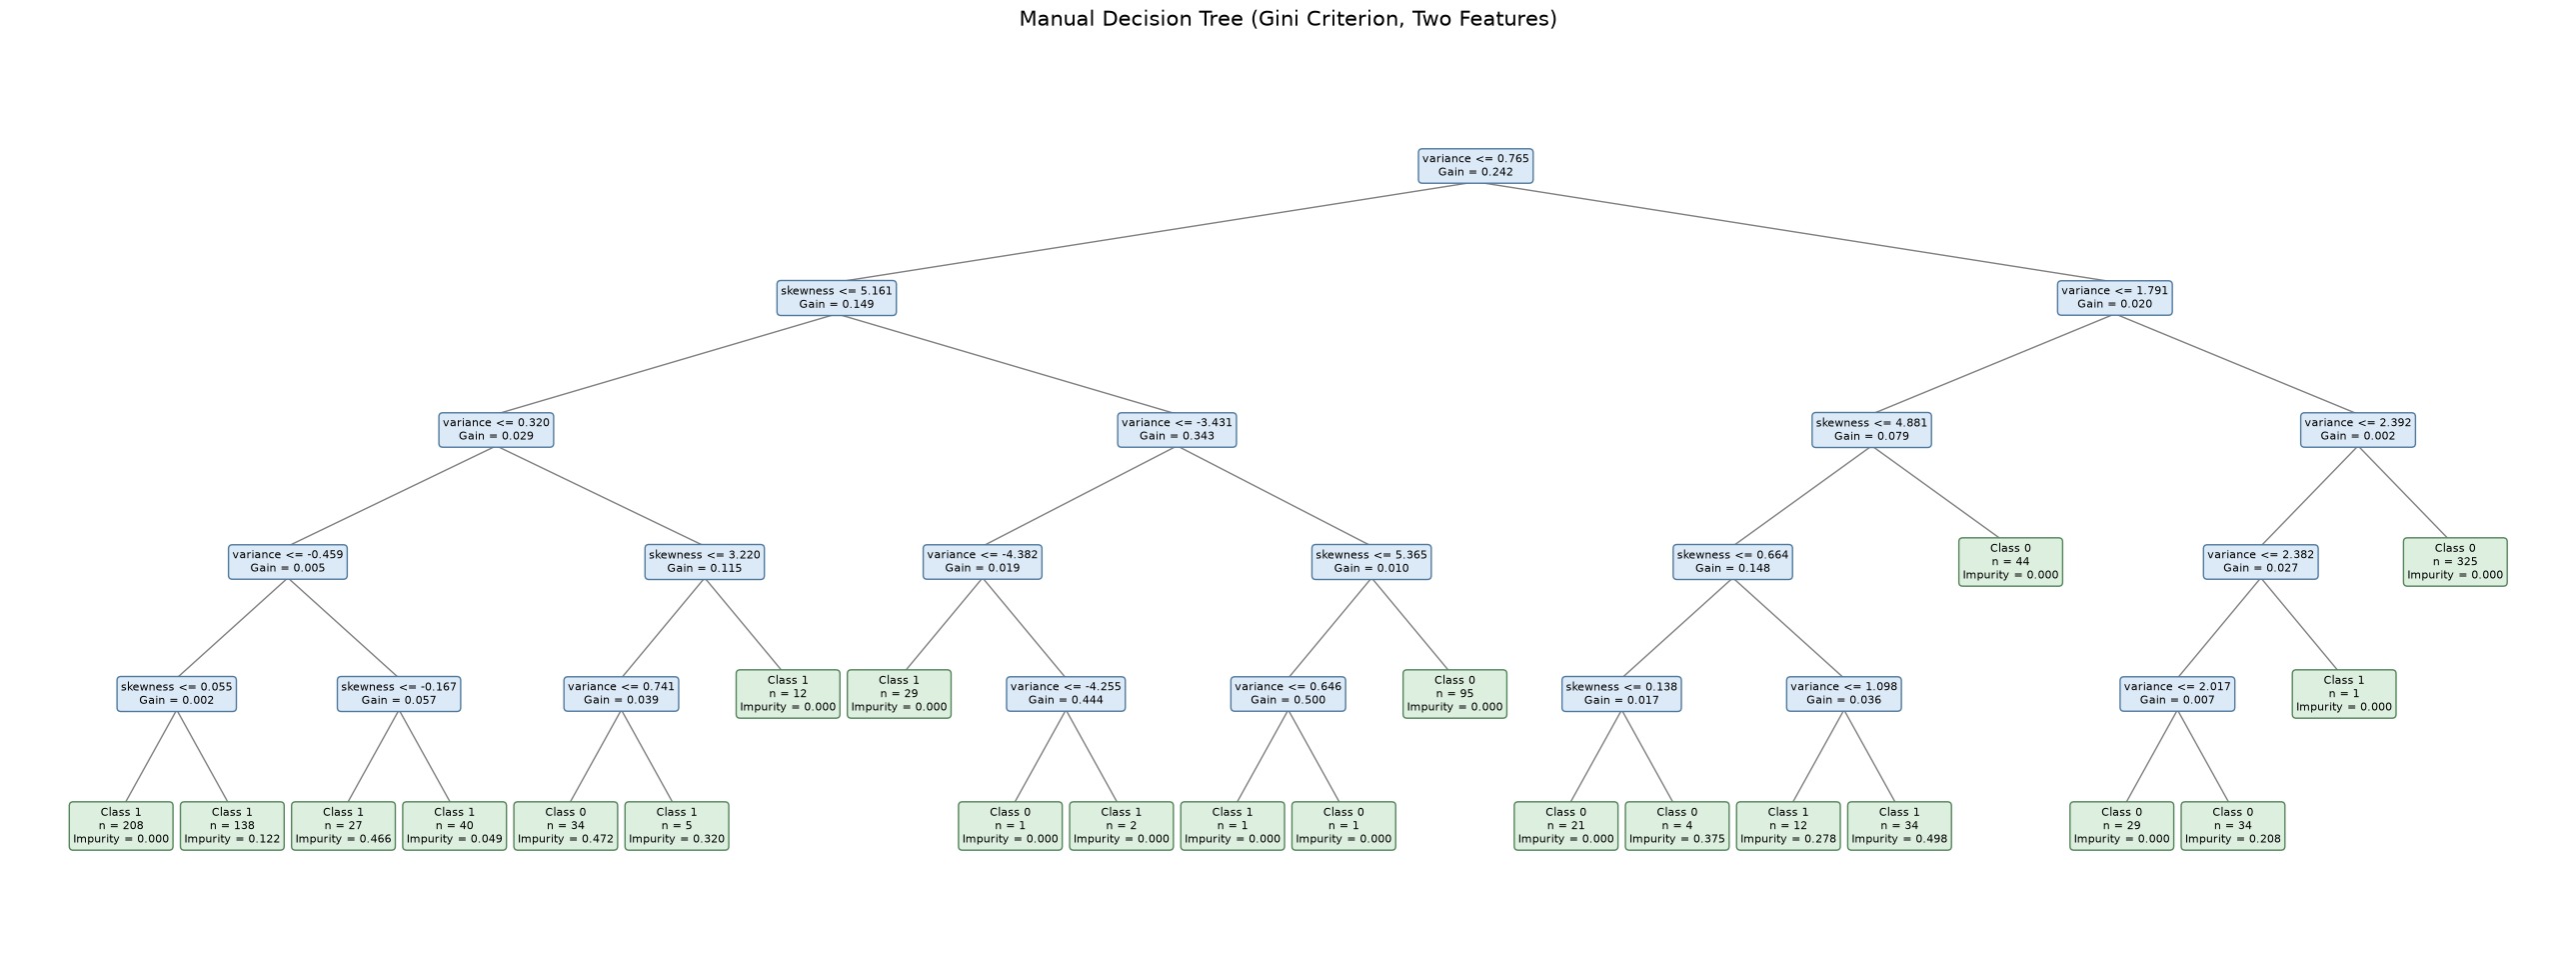

Tree saved to plots/manual_decision_tree.png


In [14]:

# Cell 12: Visualize the manual Decision Tree

import os
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

# Assign each node a position for drawing
leaf_counter = [0]

def assign_tree_positions(node, depth=0):
    if node["type"] == "leaf":
        x = leaf_counter[0] * 2.0
        leaf_counter[0] += 1
    else:
        left_x = assign_tree_positions(node["left"], depth + 1)
        right_x = assign_tree_positions(node["right"], depth + 1)
        x = (left_x + right_x) / 2

    node["_plot_x"] = x
    node["_plot_y"] = -depth
    return x


assign_tree_positions(manual_tree_2d.root_)

number_of_leaves = manual_tree_2d.get_n_leaves()

fig, ax = plt.subplots(
    figsize=(max(18, number_of_leaves * 1.5), 12)
)

def draw_tree(node):
    x = node["_plot_x"]
    y = node["_plot_y"]

    if node["type"] == "node":

        left = node["left"]
        right = node["right"]

        # Draw the connecting branches
        ax.plot(
            [x, left["_plot_x"]],
            [y - 0.12, left["_plot_y"] + 0.12],
            color="gray",
            linewidth=1
        )

        ax.plot(
            [x, right["_plot_x"]],
            [y - 0.12, right["_plot_y"] + 0.12],
            color="gray",
            linewidth=1
        )

        label = (
            f'{node["feature_name"]} <= '
            f'{node["threshold"]:.3f}\n'
            f'Gain = {node["gain"]:.3f}'
        )

        ax.text(
            x, y, label,
            ha="center", va="center", fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="#DCEAF7",
                edgecolor="#50799E"
            )
        )

        draw_tree(left)
        draw_tree(right)

    else:
        label = (
            f'Class {node["prediction"]}\n'
            f'n = {node["samples"]}\n'
            f'Impurity = {node["impurity"]:.3f}'
        )

        ax.text(
            x, y, label,
            ha="center", va="center", fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="#DDF0DF",
                edgecolor="#54845A"
            )
        )


draw_tree(manual_tree_2d.root_)

ax.set_title(
    "Manual Decision Tree (Gini Criterion, Two Features)",
    fontsize=15
)
ax.set_xlim(-2, number_of_leaves * 2)
ax.set_ylim(-manual_tree_2d.get_depth() - 1, 1)
ax.axis("off")

plt.savefig(
    "plots/manual_decision_tree.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print("Tree saved to plots/manual_decision_tree.png")


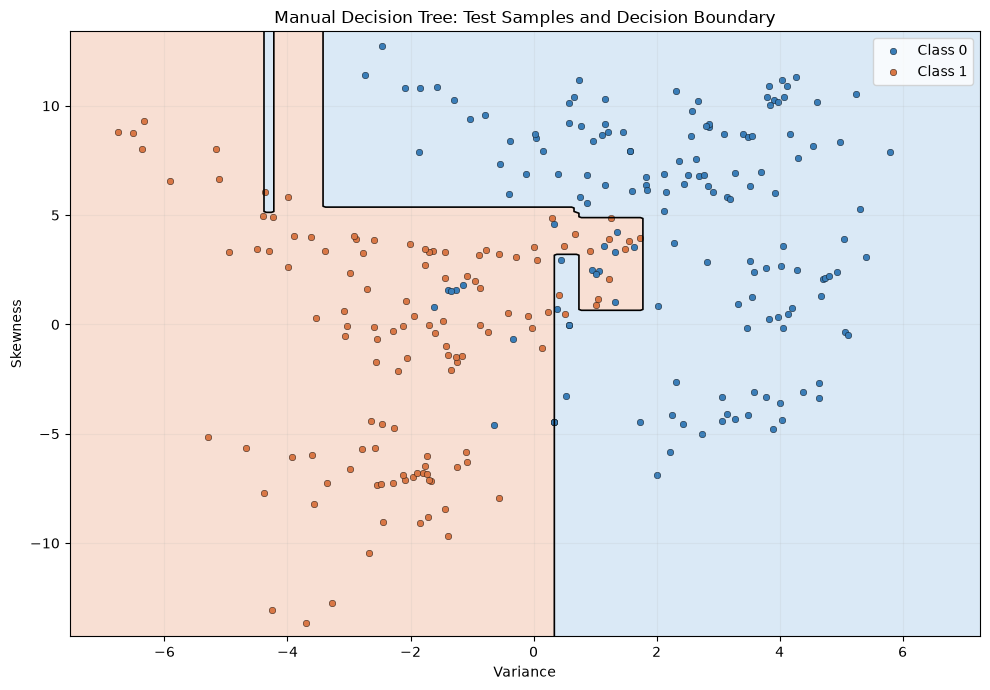

Decision boundary saved to plots/manual_tree_decision_boundary.png


In [15]:

# Cell 13: Plot the manual Decision Tree decision boundary

from matplotlib.colors import ListedColormap

# Use the ranges of the training data to build a plotting grid
X_plot = X_train_2d.to_numpy()
X_test_plot = X_test_2d.to_numpy()

x_min = X_plot[:, 0].min() - 0.5
x_max = X_plot[:, 0].max() + 0.5
y_min = X_plot[:, 1].min() - 0.5
y_max = X_plot[:, 1].max() + 0.5

# Each grid point represents one possible pair of feature values
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.08),
    np.arange(y_min, y_max, 0.08)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predict the class at every grid point
Z = manual_tree_2d.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))

background_colors = ListedColormap(["#D6E7F5", "#F8DCCF"])

ax.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    cmap=background_colors,
    alpha=0.9
)

# Draw the boundary between the predicted regions
ax.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black",
    linewidths=1.2
)

# Show the held-out test samples
y_test_array = np.asarray(y_test)

for label, color, name in [
    (0, "#397DB8", "Class 0"),
    (1, "#D97745", "Class 1")
]:
    mask = y_test_array == label

    ax.scatter(
        X_test_plot[mask, 0],
        X_test_plot[mask, 1],
        c=color,
        label=name,
        edgecolors="black",
        linewidths=0.3,
        s=22
    )

ax.set_xlabel("Variance")
ax.set_ylabel("Skewness")
ax.set_title("Manual Decision Tree: Test Samples and Decision Boundary")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.savefig(
    "plots/manual_tree_decision_boundary.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print("Decision boundary saved to plots/manual_tree_decision_boundary.png")


In [16]:

# Cell 14: Train scikit-learn Decision Tree for comparison

manual_start = time.perf_counter()

manual_tree_2d = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)
manual_tree_2d.fit(X_train_2d, y_train)

manual_train_time = time.perf_counter() - manual_start

manual_start = time.perf_counter()
manual_predictions_2d = manual_tree_2d.predict(X_test_2d)
manual_prediction_time = time.perf_counter() - manual_start

# Train scikit-learn's Decision Tree separately
sklearn_tree_2d = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_start = time.perf_counter()
sklearn_tree_2d.fit(X_train_2d, y_train)
sklearn_train_time = time.perf_counter() - sklearn_start

sklearn_start = time.perf_counter()
sklearn_predictions_2d = sklearn_tree_2d.predict(X_test_2d)
sklearn_prediction_time = time.perf_counter() - sklearn_start

comparison_2d = pd.DataFrame({
    "Model": ["Manual Decision Tree", "Scikit-learn Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, manual_predictions_2d),
        accuracy_score(y_test, sklearn_predictions_2d)
    ],
    "Training Time (seconds)": [
        manual_train_time,
        sklearn_train_time
    ],
    "Prediction Time (seconds)": [
        manual_prediction_time,
        sklearn_prediction_time
    ]
})

display(comparison_2d.round(5))

print(
    "Predictions identical:",
    np.array_equal(
        manual_predictions_2d,
        sklearn_predictions_2d
    )
)


,Model,Accuracy,Training Time (seconds),Prediction Time (seconds)
0,Manual Decision Tree,0.93091,1.87405,0.00151
1,Scikit-learn Decision Tree,0.93091,0.01440,0.00450


Predictions identical: True


In [17]:

# Cell 15: Explore criterion and maximum depth

os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

depth_values = [2, 3, 5]
criteria = ["gini", "entropy"]

experiment_results = []

for criterion in criteria:
    for depth in depth_values:

        # -------------------------------
        # Manual Decision Tree
        # -------------------------------
        manual_model = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth,
            min_samples_split=2
        )

        start = time.perf_counter()
        manual_model.fit(X_train_2d, y_train)
        manual_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        manual_train_predictions = manual_model.predict(X_train_2d)
        manual_test_predictions = manual_model.predict(X_test_2d)
        manual_predict_time = time.perf_counter() - start

        experiment_results.append({
            "Model": "Manual",
            "Criterion": criterion,
            "Max Depth": depth,
            "Actual Depth": manual_model.get_depth(),
            "Leaves": manual_model.get_n_leaves(),
            "Train Accuracy": accuracy_score(
                y_train, manual_train_predictions
            ),
            "Test Accuracy": accuracy_score(
                y_test, manual_test_predictions
            ),
            "Training Time (s)": manual_fit_time,
            "Prediction Time (s)": manual_predict_time
        })

        # -------------------------------
        # Scikit-learn Decision Tree
        # -------------------------------
        sklearn_model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        start = time.perf_counter()
        sklearn_model.fit(X_train_2d, y_train)
        sklearn_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        sklearn_train_predictions = sklearn_model.predict(X_train_2d)
        sklearn_test_predictions = sklearn_model.predict(X_test_2d)
        sklearn_predict_time = time.perf_counter() - start

        experiment_results.append({
            "Model": "Scikit-learn",
            "Criterion": criterion,
            "Max Depth": depth,
            "Actual Depth": sklearn_model.get_depth(),
            "Leaves": sklearn_model.get_n_leaves(),
            "Train Accuracy": accuracy_score(
                y_train, sklearn_train_predictions
            ),
            "Test Accuracy": accuracy_score(
                y_test, sklearn_test_predictions
            ),
            "Training Time (s)": sklearn_fit_time,
            "Prediction Time (s)": sklearn_predict_time
        })


# Convert the results to a table
depth_results = pd.DataFrame(experiment_results)

# Save the results
depth_results.to_csv(
    "results/decision_tree_depth_criterion_comparison.csv",
    index=False
)

display(
    depth_results.round(4).sort_values(
        ["Criterion", "Max Depth", "Model"]
    ).reset_index(drop=True)
)

print("Results saved to results/decision_tree_depth_criterion_comparison.csv")


,Model,Criterion,Max Depth,Actual Depth,Leaves,Train Accuracy,Test Accuracy,Training Time (s),Prediction Time (s)
0,Manual,entropy,2,2,4,0.9015,0.8764,0.5267,0.0016
1,Scikit-learn,entropy,2,2,4,0.9015,0.8764,0.0030,0.0032
2,Manual,entropy,3,3,7,0.9289,0.9091,0.6897,0.0021
3,Scikit-learn,entropy,3,3,7,0.9289,0.9091,0.0032,0.0021
4,Manual,entropy,5,5,18,0.9480,0.9345,0.9090,0.0035
5,Scikit-learn,entropy,5,5,18,0.9480,0.9345,0.0070,0.0030
6,Manual,gini,2,2,4,0.9015,0.8764,1.0417,0.0039
7,Scikit-learn,gini,2,2,4,0.9015,0.8764,0.0080,0.0195
8,Manual,gini,3,3,8,0.9289,0.9091,1.0057,0.0022
9,Scikit-learn,gini,3,3,8,0.9289,0.9091,0.0035,0.0023


Results saved to results/decision_tree_depth_criterion_comparison.csv


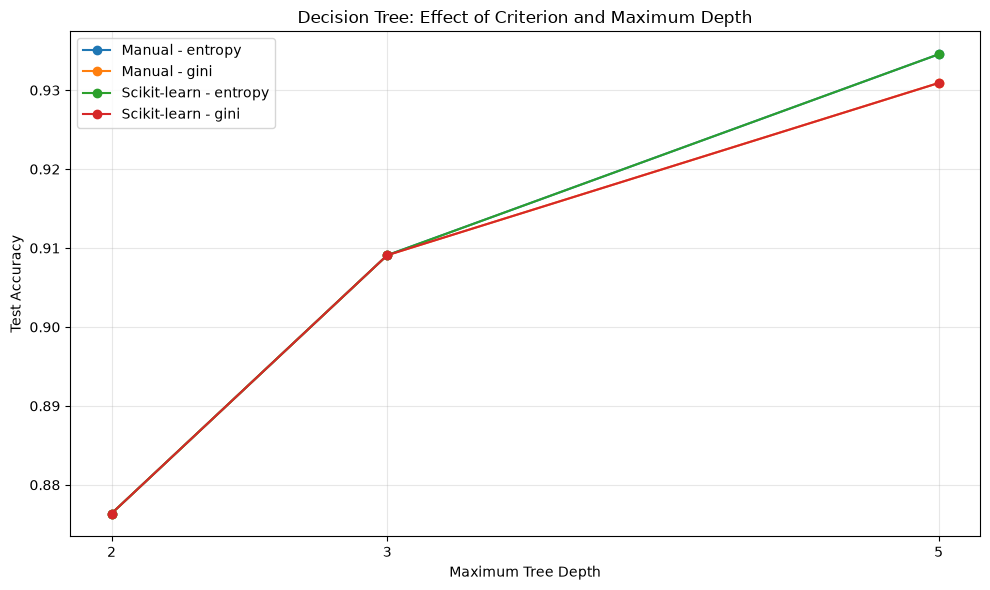

Depth comparison plot saved.


In [18]:

# Cell 16: Plot test accuracy versus tree depth

fig, ax = plt.subplots(figsize=(10, 6))

for (model_name, criterion), group in depth_results.groupby(
    ["Model", "Criterion"]
):
    group = group.sort_values("Max Depth")

    ax.plot(
        group["Max Depth"],
        group["Test Accuracy"],
        marker="o",
        label=f"{model_name} - {criterion}"
    )

ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("Test Accuracy")
ax.set_title("Decision Tree: Effect of Criterion and Maximum Depth")
ax.set_xticks(depth_values)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "plots/decision_tree_depth_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Depth comparison plot saved.")


In [19]:

# Cell 17: Scale SVM features and map labels to -1 and +1

# Fit the scaler using training data only
scaler_svm = StandardScaler()

X_train_svm = scaler_svm.fit_transform(X_train_2d)

# Reuse the same training statistics for test data
X_test_svm = scaler_svm.transform(X_test_2d)

# Map class 0 -> -1 and class 1 -> +1
y_train_svm = np.where(
    np.asarray(y_train) == 1, 1, -1
)

y_test_svm = np.where(
    np.asarray(y_test) == 1, 1, -1
)

print("Training features shape:", X_train_svm.shape)
print("Testing features shape:", X_test_svm.shape)

print("\nTraining feature means:")
print(X_train_svm.mean(axis=0).round(4))

print("\nTraining feature standard deviations:")
print(X_train_svm.std(axis=0).round(4))

print("\nTraining SVM labels:")
print(np.unique(y_train_svm, return_counts=True))

print("\nTesting SVM labels:")
print(np.unique(y_test_svm, return_counts=True))


Training features shape: (1097, 2)
Testing features shape: (275, 2)

Training feature means:
[-0.  0.]

Training feature standard deviations:
[1. 1.]

Training SVM labels:
(array([-1,  1]), array([609, 488]))

Testing SVM labels:
(array([-1,  1]), array([153, 122]))


In [30]:

# Cell 18: Linear Soft-Margin SVM from scratch

class ManualLinearSVM:

    def __init__(self, C=1.0, learning_rate=0.01, iterations=3000):
        if C <= 0:
            raise ValueError("C must be positive.")
        if learning_rate <= 0:
            raise ValueError("Learning rate must be positive.")
        if iterations < 1:
            raise ValueError("Iterations must be at least 1.")

        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations

    def fit(self, X, y):
        """Train the linear SVM using batch subgradient descent."""

        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim != 2 or len(X) != len(y) or len(y) == 0:
            raise ValueError("X and y must have matching, nonempty rows.")

        if not np.all(np.isin(y, [-1, 1])):
            raise ValueError("Labels must be -1 and +1.")

        n_samples, n_features = X.shape

        # Initialize the parameters
        self.w_ = np.zeros(n_features)
        self.b_ = 0.0
        self.loss_history_ = []

        # Optimize the SVM objective
        for iteration in range(self.iterations):

            # Decision scores of all training samples
            scores = X @ self.w_ + self.b_

            # Signed margin: y * (w.x + b)
            margins = y * scores

            # Samples with margin below 1 contribute hinge loss
            active = margins < 1

            # Subgradients of the objective
            grad_w = (
    self.w_ / n_samples
    - self.C * (X[active].T @ y[active]) / n_samples
)

            grad_b = -self.C * np.sum(y[active]) / n_samples

            # Update weights and bias
            self.w_ -= self.learning_rate * grad_w
            self.b_ -= self.learning_rate * grad_b

            # Record the objective value after the update
            updated_scores = X @ self.w_ + self.b_

            hinge_losses = np.maximum(
                0, 1 - y * updated_scores
            )

            objective = (
    0.5 * np.dot(self.w_, self.w_) / n_samples
    + self.C * np.mean(hinge_losses)
)

            self.loss_history_.append(objective)

        return self

    def decision_function(self, X):
        """Return the signed decision scores."""

        if not hasattr(self, "w_"):
            raise RuntimeError("Train the SVM before predicting.")

        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        return X @ self.w_ + self.b_

    def predict(self, X):
        """Return predictions in {-1, +1}."""

        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)


print("Manual Linear SVM class created successfully!")



Manual Linear SVM class created successfully!


In [31]:

# Cell 19: Train and evaluate the manual linear SVM

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=3000
)

start = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
svm_train_predictions = manual_svm.predict(X_train_svm)
svm_test_predictions = manual_svm.predict(X_test_svm)
manual_svm_prediction_time = time.perf_counter() - start

print("Manual Linear SVM")
print("-----------------")
print("C:", manual_svm.C)
print("Learning rate:", manual_svm.learning_rate)
print("Iterations:", manual_svm.iterations)
print("Learned weights:", manual_svm.w_)
print("Learned bias:", manual_svm.b_)

print(
    f"Final objective: {manual_svm.loss_history_[-1]:.6f}"
)

print(
    f"Training accuracy: "
    f"{accuracy_score(y_train_svm, svm_train_predictions):.4f}"
)

print(
    f"Test accuracy: "
    f"{accuracy_score(y_test_svm, svm_test_predictions):.4f}"
)

print(
    f"Training time: {manual_svm_train_time:.4f} seconds"
)

print(
    f"Prediction time: {manual_svm_prediction_time:.4f} seconds"
)


Manual Linear SVM
-----------------
C: 1.0
Learning rate: 0.01
Iterations: 3000
Learned weights: [-1.77798767 -1.09153694]
Learned bias: -0.27164083865086547
Final objective: 0.286152
Training accuracy: 0.8797
Test accuracy: 0.8764
Training time: 0.6426 seconds
Prediction time: 0.0003 seconds


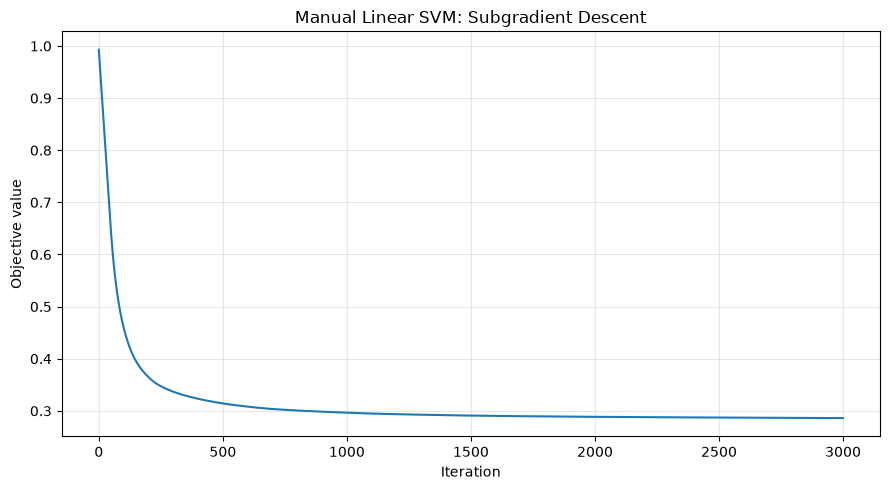

Training objective plot saved.


In [32]:

# Cell 20: Visualize the training objective

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(manual_svm.loss_history_)

ax.set_xlabel("Iteration")
ax.set_ylabel("Objective value")
ax.set_title("Manual Linear SVM: Subgradient Descent")
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "plots/manual_svm_training_objective.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Training objective plot saved.")


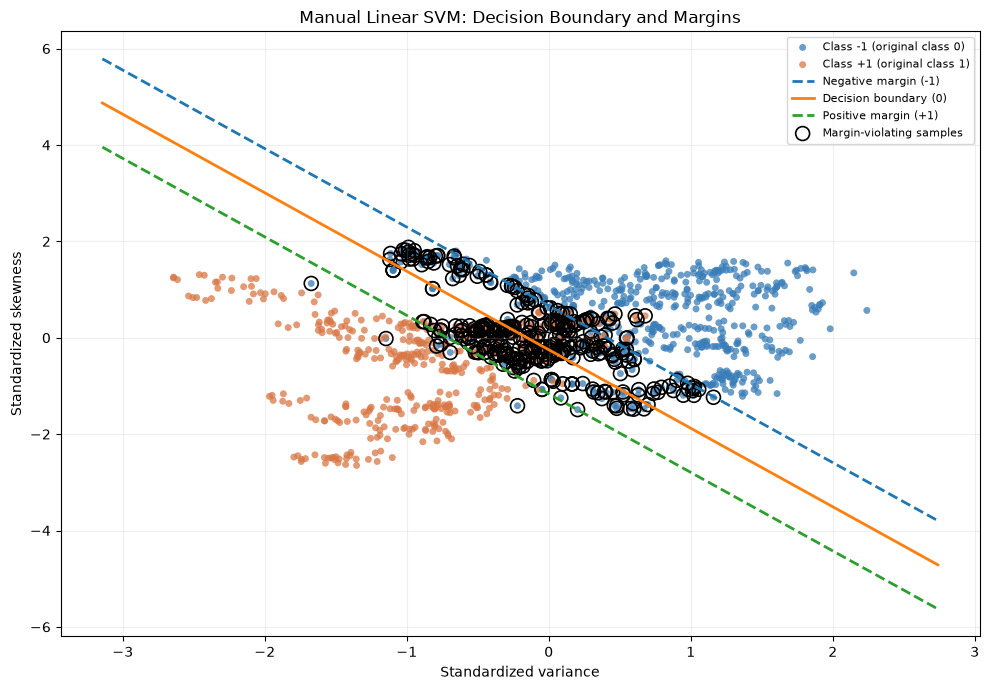

Total training samples: 1097
Margin-violating samples: 344
Misclassified training samples: 132
Correctly classified but inside/on margin: 212
Plot saved to plots/manual_svm_boundaries_margins.png


In [33]:

# Cell 21: Plot manual SVM boundary, margins, and violations

os.makedirs("plots", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 7))

# Training data in scaled feature space
X_plot_svm = X_train_svm
y_plot_svm = y_train_svm

# Plot the two classes
for label, color, name in [
    (-1, "#397DB8", "Class -1 (original class 0)"),
    (1, "#D97745", "Class +1 (original class 1)")
]:
    mask = y_plot_svm == label

    ax.scatter(
        X_plot_svm[mask, 0],
        X_plot_svm[mask, 1],
        c=color,
        label=name,
        s=25,
        alpha=0.75,
        edgecolors="none"
    )

w = manual_svm.w_
b = manual_svm.b_

# Plot f(x) = -1, 0, and +1
x_values = np.linspace(
    X_plot_svm[:, 0].min() - 0.5,
    X_plot_svm[:, 0].max() + 0.5,
    300
)

if abs(w[1]) > 1e-10:
    for level, label, style in [
        (-1, "Negative margin (-1)", "--"),
        (0, "Decision boundary (0)", "-"),
        (1, "Positive margin (+1)", "--")
    ]:
        y_values = (
            level - w[0] * x_values - b
        ) / w[1]

        ax.plot(
            x_values,
            y_values,
            linestyle=style,
            linewidth=2,
            label=label
        )

elif abs(w[0]) > 1e-10:
    # Handle a nearly vertical boundary
    for level, label, style in [
        (-1, "Negative margin (-1)", "--"),
        (0, "Decision boundary (0)", "-"),
        (1, "Positive margin (+1)", "--")
    ]:
        x_line = (level - b) / w[0]
        ax.axvline(
            x_line,
            linestyle=style,
            linewidth=2,
            label=label
        )

# Calculate signed margins for each training sample
decision_scores = manual_svm.decision_function(X_plot_svm)

signed_margins = y_plot_svm * decision_scores

# All samples with signed margin < 1 violate the margin
violations = signed_margins < 1.0
misclassified = signed_margins < 0.0

# Circle the margin-violating training samples
ax.scatter(
    X_plot_svm[violations, 0],
    X_plot_svm[violations, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2,
    label="Margin-violating samples"
)

ax.set_xlabel("Standardized variance")
ax.set_ylabel("Standardized skewness")
ax.set_title("Manual Linear SVM: Decision Boundary and Margins")
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "plots/manual_svm_boundaries_margins.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Total training samples:", len(y_plot_svm))
print("Margin-violating samples:", int(violations.sum()))
print("Misclassified training samples:", int(misclassified.sum()))
print(
    "Correctly classified but inside/on margin:",
    int(((signed_margins >= 0) & violations).sum())
)
print("Plot saved to plots/manual_svm_boundaries_margins.png")


,Model,Training Accuracy,Test Accuracy,Training Time (s),Prediction Time (s)
0,Manual Linear SVM,0.87967,0.87636,0.64261,0.00028
1,Scikit-learn Linear SVM,0.88058,0.87636,0.02789,0.00309


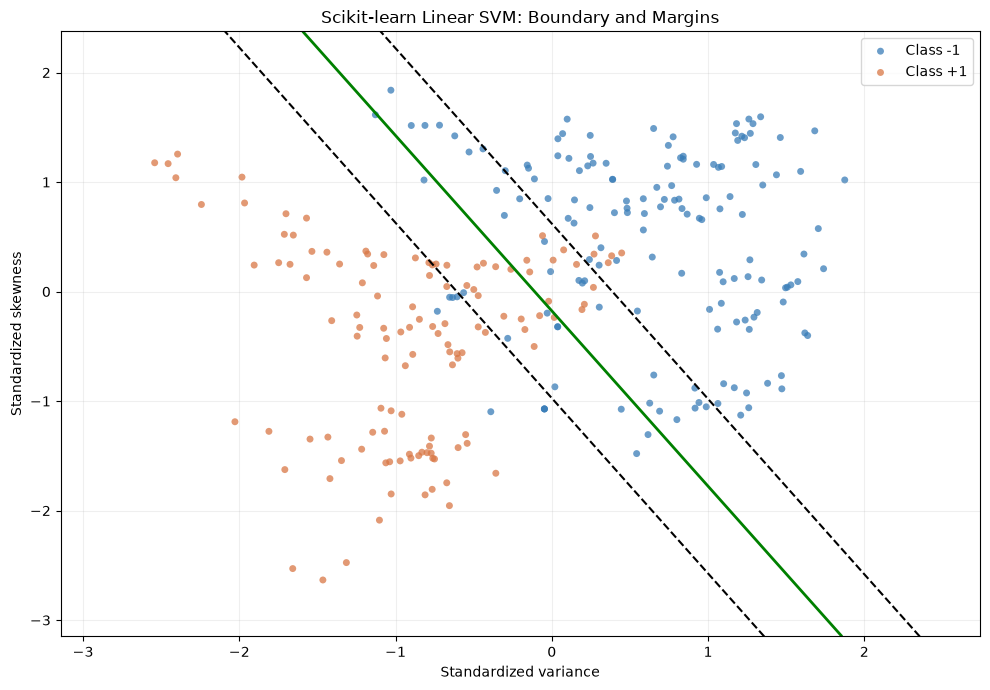

Scikit-learn SVM boundary plot saved.


In [34]:

# Cell 22: Compare manual SVM and scikit-learn linear SVM

from sklearn.svm import SVC

# Train the scikit-learn model
sklearn_svm = SVC(kernel="linear", C=1.0)

start = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sklearn_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_svm_predictions = sklearn_svm.predict(X_test_svm)
sklearn_svm_prediction_time = time.perf_counter() - start

# Evaluate both models
svm_comparison = pd.DataFrame({
    "Model": ["Manual Linear SVM", "Scikit-learn Linear SVM"],
    "Training Accuracy": [
        accuracy_score(
            y_train_svm,
            manual_svm.predict(X_train_svm)
        ),
        accuracy_score(
            y_train_svm,
            sklearn_svm.predict(X_train_svm)
        )
    ],
    "Test Accuracy": [
        accuracy_score(y_test_svm, svm_test_predictions),
        accuracy_score(y_test_svm, sklearn_svm_predictions)
    ],
    "Training Time (s)": [
        manual_svm_train_time,
        sklearn_svm_train_time
    ],
    "Prediction Time (s)": [
        manual_svm_prediction_time,
        sklearn_svm_prediction_time
    ]
})

display(svm_comparison.round(5))

# Plot the scikit-learn decision boundary
fig, ax = plt.subplots(figsize=(10, 7))

for label, color, name in [
    (-1, "#397DB8", "Class -1"),
    (1, "#D97745", "Class +1")
]:
    mask = y_test_svm == label

    ax.scatter(
        X_test_svm[mask, 0],
        X_test_svm[mask, 1],
        c=color,
        label=name,
        s=25,
        alpha=0.75,
        edgecolors="none"
    )

x_min, x_max = (
    X_train_svm[:, 0].min() - 0.5,
    X_train_svm[:, 0].max() + 0.5
)
y_min, y_max = (
    X_train_svm[:, 1].min() - 0.5,
    X_train_svm[:, 1].max() + 0.5
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Reshape decision scores into the plotting grid
scores = sklearn_svm.decision_function(grid).reshape(xx.shape)

# Plot the separating line and both margins
ax.contour(
    xx, yy, scores,
    levels=[-1, 0, 1],
    colors=["black", "green", "black"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2, 1.5]
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Standardized variance")
ax.set_ylabel("Standardized skewness")
ax.set_title("Scikit-learn Linear SVM: Boundary and Margins")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "plots/sklearn_svm_boundaries_margins.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Scikit-learn SVM boundary plot saved.")


In [35]:

# Cell 23: Study C, learning rate, and iteration count

os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

hp_records = []


def evaluate_manual_svm(model, parameter, value):
    """Train and evaluate one manual SVM configuration."""

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    fit_time = time.perf_counter() - start

    train_predictions = model.predict(X_train_svm)

    start = time.perf_counter()
    test_predictions = model.predict(X_test_svm)
    prediction_time = time.perf_counter() - start

    hp_records.append({
        "Experiment": parameter,
        "Value": value,
        "Model": "Manual SVM",
        "Train Accuracy": accuracy_score(
            y_train_svm, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test_svm, test_predictions
        ),
        "Training Time (s)": fit_time,
        "Prediction Time (s)": prediction_time,
        "Final Objective": model.loss_history_[-1]
    })


def evaluate_sklearn_svm(C_value):
    """Evaluate scikit-learn's linear SVM for a given C."""

    model = SVC(kernel="linear", C=C_value)

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    fit_time = time.perf_counter() - start

    train_predictions = model.predict(X_train_svm)

    start = time.perf_counter()
    test_predictions = model.predict(X_test_svm)
    prediction_time = time.perf_counter() - start

    hp_records.append({
        "Experiment": "C",
        "Value": C_value,
        "Model": "Scikit-learn SVM",
        "Train Accuracy": accuracy_score(
            y_train_svm, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test_svm, test_predictions
        ),
        "Training Time (s)": fit_time,
        "Prediction Time (s)": prediction_time,
        "Final Objective": np.nan
    })


# Experiment A: Change regularization C
for C_value in [0.1, 1.0, 10.0]:

    model = ManualLinearSVM(
        C=C_value,
        learning_rate=0.01,
        iterations=3000
    )

    evaluate_manual_svm(model, "C", C_value)
    evaluate_sklearn_svm(C_value)


# Experiment B: Change learning rate
for lr_value in [0.001, 0.01, 0.03]:

    model = ManualLinearSVM(
        C=1.0,
        learning_rate=lr_value,
        iterations=3000
    )

    evaluate_manual_svm(
        model, "Learning Rate", lr_value
    )


# Experiment C: Change number of iterations
for iteration_value in [500, 1000, 3000, 6000]:

    model = ManualLinearSVM(
        C=1.0,
        learning_rate=0.01,
        iterations=iteration_value
    )

    evaluate_manual_svm(
        model, "Iterations", iteration_value
    )


# Save and display all results
hp_results = pd.DataFrame(hp_records)

hp_results.to_csv(
    "results/svm_hyperparameter_experiments.csv",
    index=False
)

display(
    hp_results.round(4).sort_values(
        ["Experiment", "Value", "Model"]
    ).reset_index(drop=True)
)

print(
    "Saved to results/svm_hyperparameter_experiments.csv"
)


,Experiment,Value,Model,Train Accuracy,Test Accuracy,Training Time (s),Prediction Time (s),Final Objective
0,C,0.100,Manual SVM,0.8842,0.8873,0.6373,0.0000,0.0344
1,C,0.100,Scikit-learn SVM,0.8824,0.8836,0.0166,0.0021,NaN
2,C,1.000,Manual SVM,0.8797,0.8764,0.5699,0.0000,0.2862
3,C,1.000,Scikit-learn SVM,0.8806,0.8764,0.0208,0.0037,NaN
4,C,10.000,Manual SVM,0.8806,0.8764,0.4455,0.0000,2.8204
5,C,10.000,Scikit-learn SVM,0.8806,0.8764,0.0289,0.0058,NaN
6,Iterations,500.000,Manual SVM,0.8833,0.8873,0.0555,0.0000,0.3144
7,Iterations,1000.000,Manual SVM,0.8815,0.8873,0.1101,0.0000,0.2965
8,Iterations,3000.000,Manual SVM,0.8797,0.8764,0.3026,0.0000,0.2862
9,Iterations,6000.000,Manual SVM,0.8778,0.8800,0.6519,0.0000,0.2845


Saved to results/svm_hyperparameter_experiments.csv


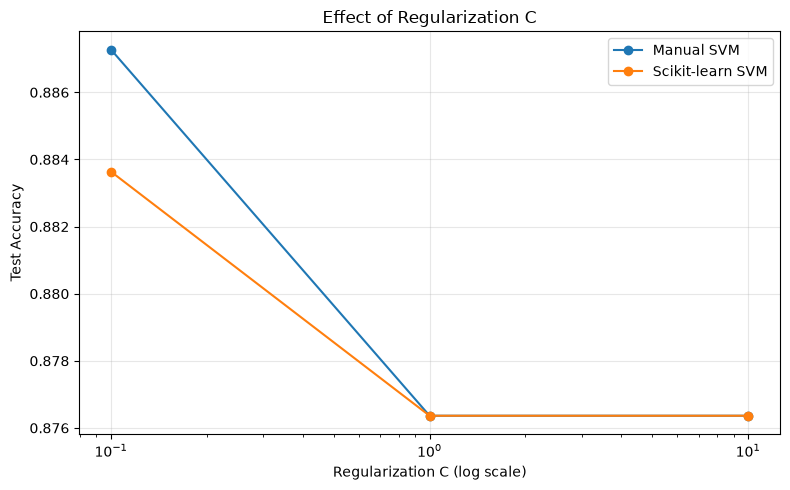

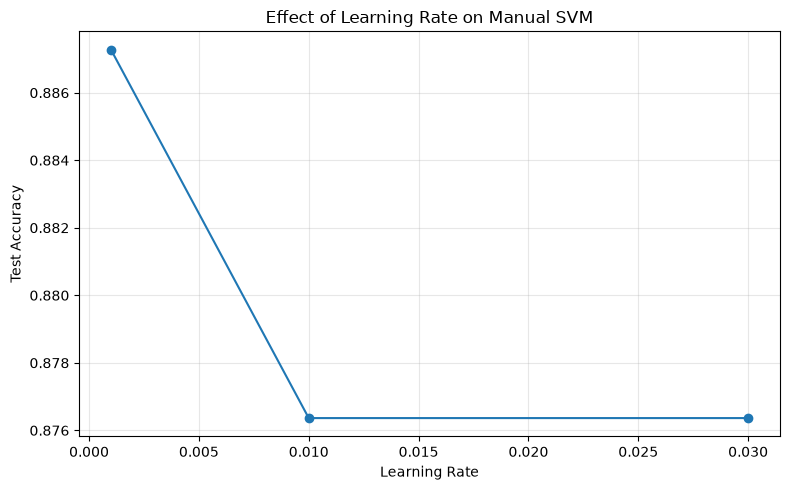

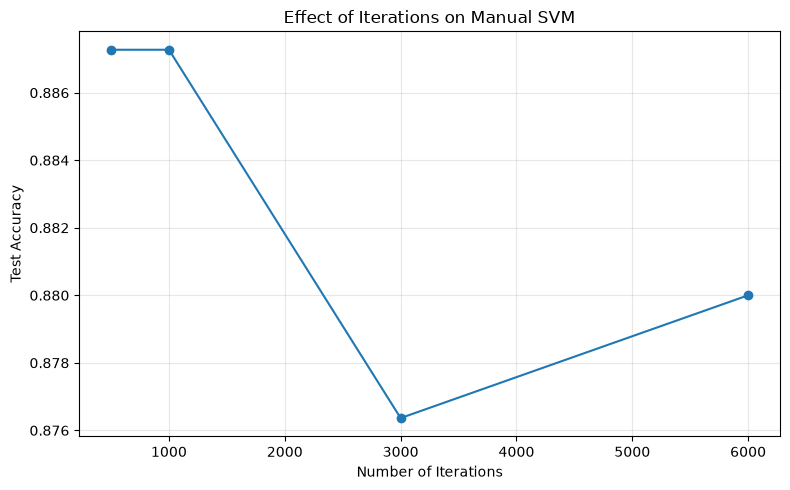

All three hyperparameter plots saved.


In [36]:

# Cell 24: Visualize SVM hyperparameter experiments

# Plot 1: Effect of C
c_results = hp_results[hp_results["Experiment"] == "C"]

fig, ax = plt.subplots(figsize=(8, 5))

for model_name, group in c_results.groupby("Model"):
    group = group.sort_values("Value")

    ax.plot(
        group["Value"],
        group["Test Accuracy"],
        marker="o",
        label=model_name
    )

ax.set_xscale("log")
ax.set_xlabel("Regularization C (log scale)")
ax.set_ylabel("Test Accuracy")
ax.set_title("Effect of Regularization C")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plots/svm_C_experiment.png", dpi=180)
plt.show()


# Plot 2: Effect of learning rate
lr_results = hp_results[
    hp_results["Experiment"] == "Learning Rate"
].sort_values("Value")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    lr_results["Value"],
    lr_results["Test Accuracy"],
    marker="o"
)

ax.set_xlabel("Learning Rate")
ax.set_ylabel("Test Accuracy")
ax.set_title("Effect of Learning Rate on Manual SVM")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plots/svm_learning_rate_experiment.png", dpi=180)
plt.show()


# Plot 3: Effect of iterations
iteration_results = hp_results[
    hp_results["Experiment"] == "Iterations"
].sort_values("Value")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    iteration_results["Value"],
    iteration_results["Test Accuracy"],
    marker="o"
)

ax.set_xlabel("Number of Iterations")
ax.set_ylabel("Test Accuracy")
ax.set_title("Effect of Iterations on Manual SVM")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plots/svm_iterations_experiment.png", dpi=180)
plt.show()

print("All three hyperparameter plots saved.")


Dataset shape: (1000, 2)
Class distribution: [500 500]


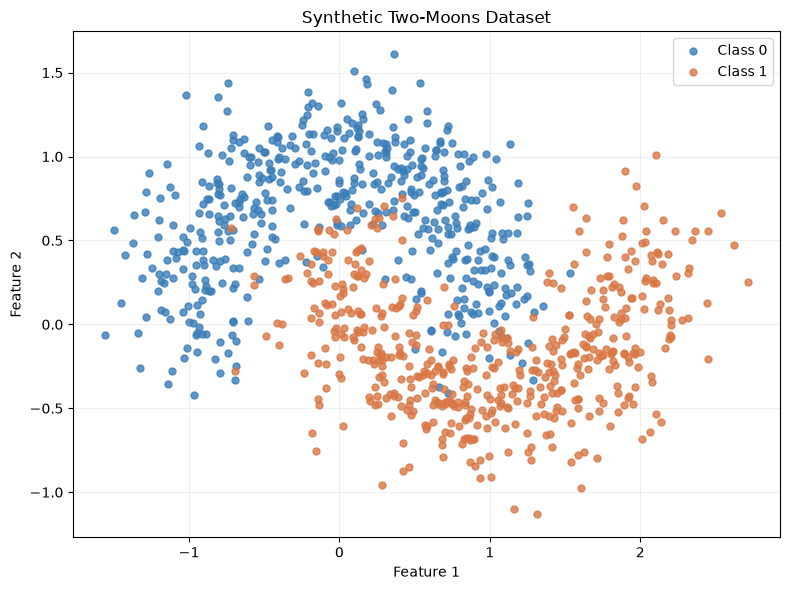

In [37]:

# Cell 25: Generate a nonlinear two-moons dataset

from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

print("Dataset shape:", X_moons.shape)
print("Class distribution:", np.bincount(y_moons))

# Visualize the generated dataset
fig, ax = plt.subplots(figsize=(8, 6))

for label, color, name in [
    (0, "#397DB8", "Class 0"),
    (1, "#D97745", "Class 1")
]:
    mask = y_moons == label

    ax.scatter(
        X_moons[mask, 0],
        X_moons[mask, 1],
        c=color,
        label=name,
        s=25,
        alpha=0.8
    )

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Synthetic Two-Moons Dataset")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("plots/two_moons_dataset.png", dpi=180)
plt.show()


In [39]:

# Cell 26: Split and scale the two-moons data

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.20,
        random_state=42,
        stratify=y_moons
    )
)

moons_scaler = StandardScaler()

X_moons_train_scaled = moons_scaler.fit_transform(
    X_moons_train
)

X_moons_test_scaled = moons_scaler.transform(
    X_moons_test
)

print("Training shape:", X_moons_train_scaled.shape)
print("Testing shape:", X_moons_test_scaled.shape)
print("Training labels:", np.bincount(y_moons_train))
print("Testing labels:", np.bincount(y_moons_test))


Training shape: (800, 2)
Testing shape: (200, 2)
Training labels: [400 400]
Testing labels: [100 100]


In [40]:

# Cell 27: Train and compare three SVM kernels

kernel_models = {
    "Linear": SVC(
        kernel="linear",
        C=1.0
    ),
    "Polynomial": SVC(
        kernel="poly",
        degree=3,
        C=1.0,
        gamma="scale"
    ),
    "RBF": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
}

kernel_results = []
kernel_prediction_cache = {}

for model_name, model in kernel_models.items():

    # Train the model
    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    # Predict training data
    train_predictions = model.predict(X_moons_train_scaled)

    # Predict unseen test data
    start = time.perf_counter()
    test_predictions = model.predict(X_moons_test_scaled)
    prediction_time = time.perf_counter() - start

    kernel_prediction_cache[model_name] = test_predictions

    # Record classification metrics
    kernel_results.append({
        "Kernel": model_name,
        "Accuracy": accuracy_score(
            y_moons_test, test_predictions
        ),
        "Precision": precision_score(
            y_moons_test, test_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, test_predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, test_predictions,
            zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

kernel_comparison = pd.DataFrame(kernel_results)

kernel_comparison.to_csv(
    "results/kernel_svm_comparison.csv",
    index=False
)

display(kernel_comparison.round(4))

print("Results saved to results/kernel_svm_comparison.csv")


,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Linear,0.915,0.9368,0.89,0.9128,0.0350,0.0037
1,Polynomial,0.905,0.9010,0.91,0.9055,0.0175,0.0027
2,RBF,0.965,0.9604,0.97,0.9652,0.0253,0.0069


Results saved to results/kernel_svm_comparison.csv


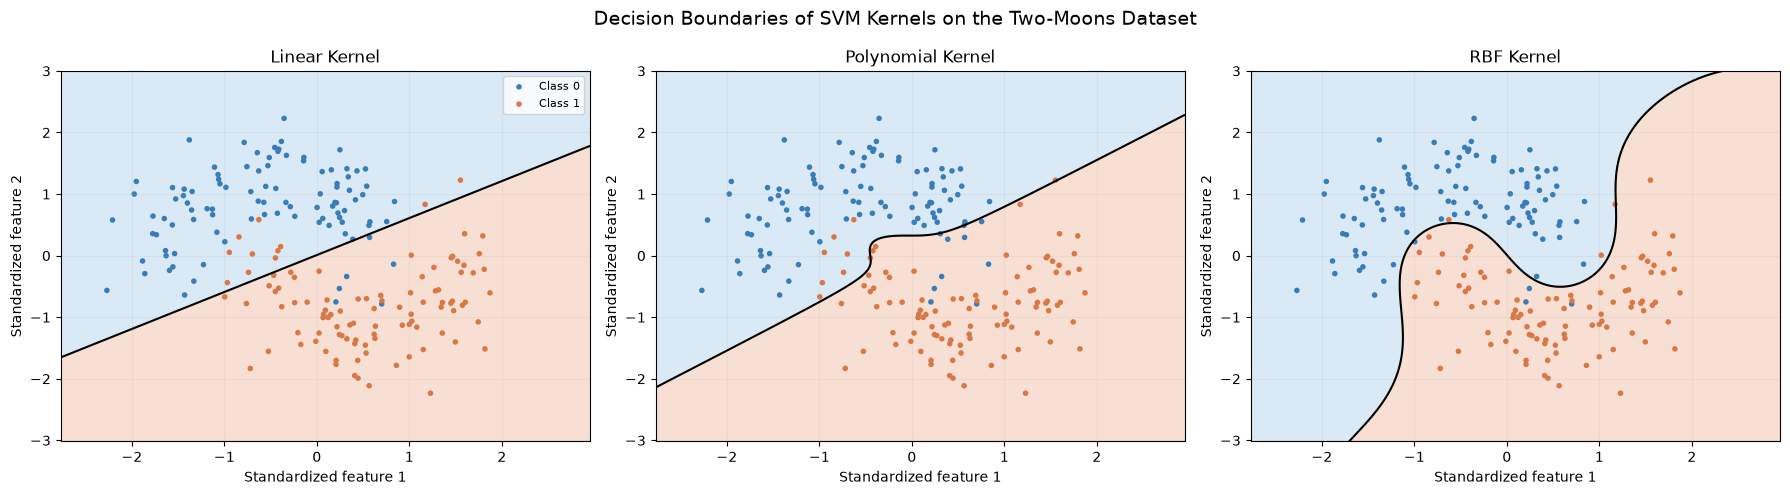

Kernel decision-boundary plot saved.


In [41]:

# Cell 28: Plot linear, polynomial, and RBF kernel boundaries

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Shared plotting range across the scaled two-feature data
all_X_moons = np.vstack([
    X_moons_train_scaled,
    X_moons_test_scaled
])

x_min = all_X_moons[:, 0].min() - 0.5
x_max = all_X_moons[:, 0].max() + 0.5
y_min = all_X_moons[:, 1].min() - 0.5
y_max = all_X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

from matplotlib.colors import ListedColormap

region_colors = ListedColormap(["#D6E7F5", "#F8DCCF"])

for ax, (model_name, model) in zip(
    axes, kernel_models.items()
):

    # Class prediction at each grid point
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap=region_colors,
        alpha=0.9
    )

    # Draw the decision boundary
    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=1.5
    )

    # Plot the same test observations for every model
    for label, color, name in [
        (0, "#397DB8", "Class 0"),
        (1, "#D97745", "Class 1")
    ]:
        mask = y_moons_test == label

        ax.scatter(
            X_moons_test_scaled[mask, 0],
            X_moons_test_scaled[mask, 1],
            c=color,
            label=name,
            s=16,
            edgecolors="none"
        )

    ax.set_title(f"{model_name} Kernel")
    ax.set_xlabel("Standardized feature 1")
    ax.set_ylabel("Standardized feature 2")
    ax.grid(alpha=0.15)

axes[0].legend(fontsize=8)

fig.suptitle(
    "Decision Boundaries of SVM Kernels on the Two-Moons Dataset",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "plots/kernel_svm_decision_boundaries.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print("Kernel decision-boundary plot saved.")


In [42]:

# Cell 29: Prepare all four features for the final SVM comparison

# Fit scaling statistics using only the training samples
final_scaler = StandardScaler()

X_train_all_scaled = final_scaler.fit_transform(X_train)
X_test_all_scaled = final_scaler.transform(X_test)

# Encode labels for our manual SVM
y_train_all_svm = np.where(
    np.asarray(y_train) == 1, 1, -1
)

y_test_all_svm = np.where(
    np.asarray(y_test) == 1, 1, -1
)

print("Training features:", X_train_all_scaled.shape)
print("Testing features:", X_test_all_scaled.shape)
print("Training labels:", np.unique(y_train_all_svm))
print("Testing labels:", np.unique(y_test_all_svm))


Training features: (1097, 4)
Testing features: (275, 4)
Training labels: [-1  1]
Testing labels: [-1  1]


In [43]:

# Cell 30: Final five-model comparison on the Banknote dataset

os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

# Model 1: Manual Decision Tree using all four features
final_manual_tree = ManualDecisionTree(
    criterion="entropy",
    max_depth=5,
    min_samples_split=2
)

# Model 2: Scikit-learn Decision Tree
final_sklearn_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)

# Model 3: Manual Linear SVM using all four scaled features
final_manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=3000
)

# Model 4: Scikit-learn Linear SVM
final_linear_svm = SVC(
    kernel="linear",
    C=1.0
)

# Model 5: Scikit-learn RBF SVM
final_rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Each entry contains:
# model name, training function, training prediction function,
# test prediction function.
final_models = [
    (
        "Manual Decision Tree",
        lambda: final_manual_tree.fit(X_train, y_train),
        lambda: final_manual_tree.predict(X_train),
        lambda: final_manual_tree.predict(X_test)
    ),
    (
        "Scikit-learn Decision Tree",
        lambda: final_sklearn_tree.fit(X_train, y_train),
        lambda: final_sklearn_tree.predict(X_train),
        lambda: final_sklearn_tree.predict(X_test)
    ),
    (
        "Manual Linear SVM",
        lambda: final_manual_svm.fit(
            X_train_all_scaled, y_train_all_svm
        ),
        lambda: np.where(
            final_manual_svm.predict(X_train_all_scaled) == 1,
            1, 0
        ),
        lambda: np.where(
            final_manual_svm.predict(X_test_all_scaled) == 1,
            1, 0
        )
    ),
    (
        "Scikit-learn Linear SVM",
        lambda: final_linear_svm.fit(
            X_train_all_scaled, y_train
        ),
        lambda: final_linear_svm.predict(X_train_all_scaled),
        lambda: final_linear_svm.predict(X_test_all_scaled)
    ),
    (
        "Scikit-learn RBF SVM",
        lambda: final_rbf_svm.fit(
            X_train_all_scaled, y_train
        ),
        lambda: final_rbf_svm.predict(X_train_all_scaled),
        lambda: final_rbf_svm.predict(X_test_all_scaled)
    )
]

final_records = []

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

for name, fit_fn, train_predict_fn, test_predict_fn in final_models:

    # Measure training time
    start = time.perf_counter()
    fit_fn()
    training_time = time.perf_counter() - start

    # Training predictions for the generalization comparison
    train_predictions = train_predict_fn()

    # Measure prediction time on held-out test data only
    start = time.perf_counter()
    test_predictions = test_predict_fn()
    prediction_time = time.perf_counter() - start

    # Store results
    final_records.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train_array, train_predictions
        ),
        "Accuracy": accuracy_score(
            y_test_array, test_predictions
        ),
        "Precision": precision_score(
            y_test_array, test_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_array, test_predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test_array, test_predictions,
            zero_division=0
        ),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })


# Create and save the final comparison table
final_comparison = pd.DataFrame(final_records)

final_comparison.to_csv(
    "results/final_model_comparison.csv",
    index=False
)

display(final_comparison.round(4))

print("Final comparison saved to results/final_model_comparison.csv")


,Model,Train Accuracy,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9973,0.9855,0.9758,0.9918,0.9837,3.5726,0.0015
1,Scikit-learn Decision Tree,0.9973,0.9855,0.9758,0.9918,0.9837,0.0129,0.0036
2,Manual Linear SVM,0.9845,0.9709,0.9385,1.0000,0.9683,0.5249,0.0000
3,Scikit-learn Linear SVM,0.9863,0.9745,0.9457,1.0000,0.9721,0.0122,0.0009
4,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,1.0000,0.0122,0.0077


Final comparison saved to results/final_model_comparison.csv


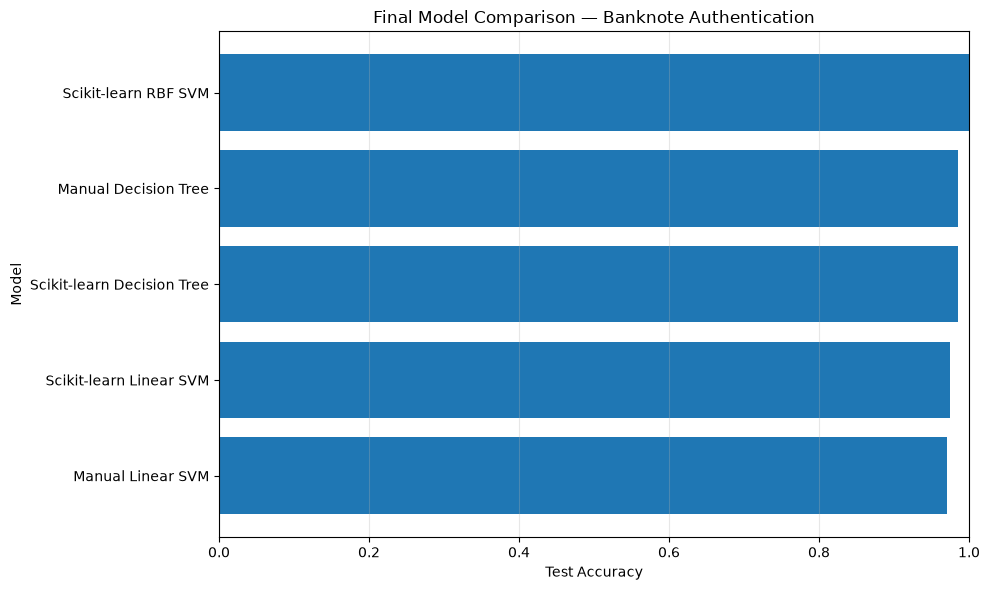

Final accuracy plot saved.


In [44]:

# Cell 31: Plot final test accuracy for all five models

plot_data = final_comparison.sort_values(
    "Accuracy", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["Model"],
    plot_data["Accuracy"]
)

ax.set_xlim(0, 1)
ax.set_xlabel("Test Accuracy")
ax.set_ylabel("Model")
ax.set_title("Final Model Comparison — Banknote Authentication")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "plots/final_model_accuracy_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Final accuracy plot saved.")
